# Steinmetz-type loss fit for TDK SIFERRIT power ferrites

Materials in this file: **N95, N27, N92, N88, N87, N97**. Choose one with `MATERIAL` in section 3. Each material has its own data (read from the datasheet plots), its own fitted coefficients and its own list of model terms.

**Data for each material** come from the three standard datasheet plots: core loss versus frequency (two or three temperatures, several flux densities), versus flux density at one frequency, and versus temperature at one frequency. All points were read from pixel positions in the plot images (digitizing error roughly 3 to 5 %).

**Model.** One joint model for all temperatures, linear in its coefficients after taking the logarithm, so it is solved with ordinary least squares:

$$\ln P_v=\sum_i\theta_i\,\phi_i(x,y,\tau),\qquad x=\ln\frac{f}{f_0},\;y=\ln\frac{\hat B}{0.1\,\mathrm T},\;\tau=\frac{T-80\,^\circ\mathrm C}{60\,^\circ\mathrm C}$$

The terms $1,x,y$ are the classic Steinmetz $k,\alpha,\beta$. The remaining terms (powers of $x$, $\tau$, and their products) let $\alpha$ and $\beta$ vary with frequency, flux density and temperature, and describe the temperature curve. For each material the terms were chosen by greedy forward selection on a leave-one-curve-out cross-validation, so each term had to improve the prediction of curves the fit had not seen. $f_0$ is a normalisation frequency (100 kHz, or 25 kHz for N27 whose data end at 200 kHz).

Units: $f$ in kHz, $\hat B$ in T, $T$ in °C, $P_v$ in kW/m³.

## 1. Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MATERIALS = {
    'N95': dict(
        notes='N95 R34 toroids: f-sweep FAL0753-8 (25/100 degC), B-sweep FAL0941-K and T-sweep FAL0752-Z at 100 kHz',
        F0=100, Tlo=25, Thi=100,
        order=['1', 'x', 'y', 't', 'x2', 'ty', 'tx', 'x3', 't2', 'tx2', 'xy', 'x2y', 't3', 't2y'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (300, 25, [14.6, 20, 25, 40, 49.7],
                [102, 151.5, 192.6, 359.4, 454]),
            (300, 100, [14.6, 20, 25, 40, 49.7],
                [95.5, 133.4, 166.8, 311.2, 395]),
            (200, 25, [16, 20, 25, 30, 40, 50, 60, 80, 100, 120, 150],
                [46.4, 61.9, 77.4, 100, 137.7, 183.6, 229.7, 348.1, 471.6, 590, 812.3]),
            (200, 100, [16, 20, 25, 30, 40, 50, 60, 80, 100, 120, 150],
                [35.9, 47.9, 59.9, 77.4, 103.2, 137.7, 172.2, 261, 377, 487, 692.3]),
            (100, 25, [15, 16, 20, 25, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250, 600],
                [8.8, 9.5, 12.9, 16.2, 20.9, 29.7, 39.6, 49.5, 72.6, 95.3, 121.2, 159, 244.8, 337.1, 1895.7]),
            (100, 100, [15, 16, 20, 25, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250, 600],
                [4.8, 5.1, 6.8, 8.5, 11, 15.2, 20.2, 25.3, 37.7, 51.9, 70.3, 103.2, 192.6, 282.7, 2487.9]),
            (50, 25, [16, 25, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250, 300],
                [1.9, 3.2, 4.2, 5.8, 7.7, 9.5, 14.2, 19.3, 23.7, 31.6, 47.9, 64.9, 95.3]),
            (50, 100, [16, 20, 25, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250, 300],
                [0.8, 1, 1.3, 1.7, 2.4, 3.2, 4.1, 6.2, 8.8, 11.7, 17.2, 31.6, 48.7, 79.9]),
            (25, 25, [100, 120, 150, 200, 400, 600, 700, 800],
                [3.6, 4.5, 6.2, 9.5, 37.7, 101.6, 151.5, 205.4]),
            (25, 100, [100, 120, 150, 200, 400, 600, 700, 800],
                [1.6, 2.3, 3.8, 7.9, 32.1, 85.2, 125.1, 169.5]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
            (200, 200, 1312.4),
            (200, 250, 1866),
            (100, 500, 1250.9),
            (50, 400, 164.2),
            (50, 500, 256.9),
            (50, 600, 408.4),
            (50, 700, 571.4),
            (25, 300, 18.7),
            (25, 500, 55.3),
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (25, 100, [25, 27, 30, 35, 40, 60, 70, 80, 90, 120, 130, 140, 150],
                [3.6, 4.3, 5.3, 7.7, 10.4, 30.5, 42.8, 58, 75.1, 130.4, 156.2, 189.1, 211.6]),
            (120, 100, [25, 27, 30, 35, 40, 60, 70, 80, 90, 120, 130, 140, 150],
                [1.6, 1.9, 2.4, 3.4, 4.7, 15.7, 25.5, 36.6, 50.7, 100.7, 129, 161.5, 187]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (200, 100, [25, 30, 35, 45, 50, 55, 60, 65, 70, 80, 90, 100, 105, 110, 115, 120, 130, 135],
                [476, 465.2, 454.7, 424.6, 415, 405.6, 396.5, 387.5, 378.8, 370.2, 366, 370.2, 378.8, 387.5, 396.5, 419.8, 454.7, 476]),
            (100, 100, [25, 30, 35, 40, 45, 50, 55, 60, 65, 80, 85, 90, 95, 110, 115, 120, 125, 135],
                [95.1, 90.9, 87.8, 82, 80.1, 75.7, 73.1, 69.9, 66.7, 59.5, 56.9, 55.6, 54.3, 54.3, 55.6, 58.2, 59.5, 66.7]),
            (50, 100, [25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 100, 105, 110, 115, 120, 125, 135],
                [18.6, 17.3, 16.4, 15.3, 14.8, 14, 13.2, 12.3, 11.8, 11, 10.5, 9.8, 9.6, 8.4, 8.4, 8.5, 8.6, 8.8, 8.9, 9.8]),
            (25, 100, [25, 30, 40, 45, 50, 55, 60, 65, 75, 80, 85, 90, 100, 105, 110, 115, 120, 125, 130, 135],
                [3.5, 3.3, 2.9, 2.7, 2.6, 2.4, 2.3, 2.1, 1.8, 1.7, 1.6, 1.6, 1.5, 1.5, 1.5, 1.5, 1.5, 1.6, 1.7, 1.8]),
        ],
    ),
    'N27': dict(
        notes='N27 R16 toroids: f-sweep FAL0324-5 (20/100 degC), B-sweep FAL0304-Q at 25 kHz, T-sweep FAL0314-X at 25 kHz',
        F0=25, Tlo=20, Thi=100,
        order=['1', 'x', 'y', 't', 't2', 'ty', 'y2', 't2x', 'x2', 'tx2'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (300, 20, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50],
                [24.22, 38.94, 54.54, 70.83, 105, 159.5, 256.5, 359.3, 577.7, 1051]),
            (300, 100, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50],
                [15.5, 25.84, 37.15, 49.23, 75.26, 118, 196.9, 283, 471.9, 899]),
            (200, 20, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [9.803, 16.12, 22.94, 30.17, 45.58, 70.61, 116.1, 165.2, 271.7, 508.5, 768.4, 1190, 1957, 2786]),
            (200, 100, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [7.341, 12.21, 17.52, 23.18, 35.36, 55.32, 92.01, 132, 219.6, 416.8, 635.8, 994.7, 1654, 2374]),
            (100, 20, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [2.424, 3.938, 5.556, 7.257, 10.85, 16.63, 27.02, 38.12, 61.92, 114.1, 170.7, 261.5, 424.8, 599.4]),
            (100, 100, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [1.48, 2.476, 3.567, 4.736, 7.26, 11.42, 19.11, 27.53, 46.06, 88.11, 135.1, 212.4, 355.4, 512.1]),
            (50, 20, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [0.5594, 0.9103, 1.286, 1.681, 2.519, 3.866, 6.292, 8.889, 14.47, 26.72, 40.03, 61.43, 99.98, 141.2]),
            (50, 100, [10, 15, 20, 30, 50, 70, 100, 150, 200],
                [2.234, 3.823, 5.598, 9.581, 18.86, 29.46, 47.26, 80.89, 118.4]),
            (25, 20, [2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200],
                [0.1145, 0.1883, 0.268, 0.3523, 0.5322, 0.8242, 1.355, 1.928, 3.17, 5.93, 8.959, 13.87, 22.81, 32.46]),
            (25, 100, [10, 15, 20, 30, 50, 70, 100, 150, 200],
                [0.4327, 0.7531, 1.116, 1.942, 3.904, 6.184, 10.07, 17.53, 25.97]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (20, 25, [28, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 290],
                [3.791, 5.936, 7.764, 12.16, 17.54, 23.92, 31.28, 48.99, 70.68, 110.7, 197.4, 309.1, 416.6]),
            (100, 25, [28, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 290],
                [2.234, 3.59, 4.768, 7.663, 11.29, 15.67, 20.81, 33.45, 49.29, 79.22, 146, 234.7, 321.8]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (300, 25, [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
                [463.4, 440.9, 421.9, 403, 383.8, 371.4, 361, 351.7, 344.3, 338.9, 336.1, 333.9, 332.9, 334.9, 338.5, 343.3, 349.7, 358, 369, 381.4]),
            (200, 25, [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
                [204.4, 191.2, 182.5, 175.3, 169, 164.1, 160, 156.6, 154.5, 152.9, 151.9, 151.8, 152, 153, 155.2, 158.1, 161.5, 165.5, 171.2, 177.8]),
            (100, 25, [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
                [56.38, 52.63, 49.48, 46.49, 43.64, 41.21, 38.86, 36.62, 34.98, 33.73, 32.85, 32.3, 32.15, 32.29, 32.61, 33.28, 34.3, 35.56, 36.99, 38.18]),
            (50, 25, [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
                [10.64, 10.27, 9.75, 9.178, 8.687, 8.264, 7.839, 7.433, 7.145, 6.869, 6.658, 6.546, 6.463, 6.461, 6.537, 6.624, 6.725, 6.919, 7.17, 7.399]),
            (25, 25, [25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115],
                [2.28, 2.119, 1.986, 1.871, 1.758, 1.665, 1.577, 1.507, 1.452, 1.413, 1.385, 1.372, 1.375, 1.387, 1.416, 1.463, 1.519, 1.589, 1.679]),
        ],
    ),
    'N92': dict(
        notes='N92 R34 toroids; f-sweep FAL0615-P (25/100 degC), B-sweep FAL0943-E and T-sweep FAL0614-G at 100 kHz',
        F0=100, Tlo=25, Thi=100,
        order=['1', 'x', 'y', 't', 't2', 't3', 't2x', 'ty', 'x3', 'txy', 'x2', 'x2y', 'y2', 't2y'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (300, 100, [27, 45],
                [178, 363]),
            (300, 25, [27, 30, 35, 40, 45, 50],
                [437.4, 497.7, 601.8, 714.2, 843.2, 993.8]),
            (200, 100, [27, 30, 40, 50, 70, 100, 130, 160, 200, 250, 300],
                [78.2, 87.9, 124, 163, 244, 391, 577, 800, 1190, 1820, 2560]),
            (200, 25, [27, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [259.3, 291.1, 345.2, 398.3, 451, 504.6, 611.8, 719.9, 823.5, 1027, 1244, 1649, 2367, 3282, 4341]),
            (100, 100, [27, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [13.77, 15.23, 17.71, 20.19, 22.61, 25.3, 30.8, 36.67, 42.67, 56.3, 76.49, 110.5, 185.7, 276.5, 388.1, 692.8, 1105, 1649, 2328, 3163, 4230, 4840]),
            (100, 25, [27, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [94.94, 104, 119.3, 133.7, 147.6, 162.1, 187.4, 210.5, 234.7, 284, 337.7, 422.7, 593, 785, 1005, 1540, 2204, 3000, 3951, 5064, 6346, 7054]),
            (50, 100, [27, 30, 40, 50, 70, 100, 130, 200, 250, 300, 400, 500, 600, 700, 800],
                [2.06, 2.25, 2.87, 3.56, 5.13, 8.15, 11.4, 28.97, 47.95, 71.05, 138.2, 227.5, 342.7, 489.9, 752.6]),
            (50, 25, [27, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [24.34, 26.65, 30.34, 33.84, 36.87, 39.49, 44.22, 48.88, 53.13, 64.18, 70.03, 79.2, 126.9, 168.2, 214.2, 324.4, 456.2, 615.4, 800.8, 1019, 1277, 1416]),
            (25, 100, [100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [1.011, 1.505, 2.511, 4.902, 8.314, 12.94, 26.61, 47.4, 74.87, 108.9, 151.6, 198.7, 224.6]),
            (25, 25, [100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [10.28, 12.22, 15.35, 20.86, 26.89, 34.09, 50.83, 72.83, 100.3, 135.5, 180.9, 235.4, 267.2]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
            (12.5, 500, 11.39),
            (12.5, 600, 16.68),
            (12.5, 700, 22.96),
            (12.5, 800, 31.02),
            (12.5, 900, 41.8),
            (12.5, 950, 48.44),
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (25, 100, [26, 28, 30, 35, 40, 45, 60, 80, 90, 100, 120, 150, 180],
                [11.16, 13.89, 16.2, 24.04, 33.77, 44.91, 87.67, 165.6, 240.41, 296.09, 402.5, 617.27, 906.03]),
            (100, 100, [26, 28, 35, 40, 50, 60, 80, 90, 100, 150, 195],
                [1.17, 1.47, 2.68, 3.85, 8.48, 12.05, 28.03, 47.97, 62.41, 182.77, 381.02]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (200, 100, [25, 30, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 120, 130, 135],
                [1037, 988, 868, 762, 653, 562, 487, 418, 416, 432, 473, 530, 662, 804, 860]),
            (100, 100, [30, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 120, 130, 135],
                [261, 211, 181, 144, 110, 84.4, 64, 59.8, 60, 65, 77.4, 111, 151, 169]),
            (50, 100, [30, 40, 50, 60, 70, 80, 90, 95, 104, 108, 112, 116, 124, 128, 136],
                [58.4, 46.8, 37.2, 28.2, 20.5, 14.4, 9.98, 8.7, 8.48, 9.47, 11.16, 13.4, 19.31, 22.35, 28.86]),
            (25, 100, [30, 40, 50, 60, 70, 80, 90, 95, 100, 104, 112, 116, 120, 132, 136],
                [9.51, 7.98, 6.32, 4.77, 3.46, 2.38, 1.56, 1.235, 1.05, 1.157, 1.73, 2.08, 2.59, 3.87, 4.16]),
        ],
    ),
    'N88': dict(
        notes='N88 R34 toroids; f-sweep FAL0841-Q (25/100/130 degC), B-sweep FAL0840-H (frequency not stated, consistent with 100 kHz), T-sweep FAL0790-C at 100 kHz',
        F0=100, Tlo=25, Thi=100,
        order=['1', 'x', 'y', 't', 'tx', 'txy', 'ty', 't3', 'x2'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (300, 130, [25, 26, 28, 30, 45],
                [154.1, 160, 172, 187.6, 277.8]),
            (300, 100, [28, 30, 35, 40, 45],
                [174.8, 191.9, 235.9, 281.6, 334.9]),
            (300, 25, [25, 26, 28, 30, 35, 40, 45],
                [406.3, 421, 454.1, 488.3, 578, 668.6, 760.5]),
            (200, 130, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [49.9506, 52.8005, 58.6408, 64.6627, 80.47, 97.2859, 115.041, 133.68, 173.422, 216.206, 261.795, 360.671, 468.894, 646.974, 981.011, 1356.19, 1768.11]),
            (200, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [67.6289, 71.1947, 78.4662, 85.9181, 105.295, 125.671, 146.978, 169.157, 215.948, 265.739, 318.294, 430.984, 552.878, 751.228, 1118.53, 1526.48, 1970.82]),
            (200, 25, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [186.758, 195.202, 212.213, 229.376, 272.898, 317.207, 362.214, 407.849, 500.786, 595.671, 692.25, 889.768, 1092.23, 1403.6, 1939.14, 2491.35, 3057.15]),
            (100, 130, [25, 26, 28, 30, 35, 40, 45, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [6.4943, 6.8418, 7.5576, 8.3009, 10.2786, 12.4257, 14.741, 35.6204, 51.2324, 69.5579, 102.229, 170.919, 258.131, 364.726, 491.573, 639.532, 809.458, 961.783, 1002.2]),
            (100, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [11.8869, 12.4566, 13.6198, 14.8144, 17.9354, 21.2448, 24.7382, 28.412, 36.2889, 44.855, 54.095, 74.5504, 97.5837, 136.867, 214.739, 307.924, 416.35, 540.028, 679.022, 833.43, 968.132, 1003.37]),
            (100, 25, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [48.8689, 51.0856, 55.5409, 60.0231, 71.3293, 82.7546, 94.2755, 105.874, 129.254, 152.816, 176.509, 224.152, 271.998, 343.921, 463.759, 583.193, 702.031, 820.192, 937.644, 1054.38, 1147.26, 1170.41]),
            (50, 130, [26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 500],
                [1.0693, 1.1838, 1.302, 1.6136, 1.9485, 2.3069, 2.6892, 3.5268, 4.4647, 5.507, 7.9207, 10.8028, 16.0866, 27.7927, 43.7197, 64.6187, 215.537]),
            (50, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 500],
                [2.0502, 2.1722, 2.418, 2.6661, 3.295, 3.9349, 4.5854, 5.2472, 6.6084, 8.027, 9.5115, 12.7092, 16.257, 22.3429, 34.9086, 51.1397, 218.943]),
            (50, 25, [26, 28, 30, 35, 40, 45, 50, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [10.1479, 11.016, 11.8857, 14.0632, 16.2417, 18.4175, 20.5882, 29.1927, 33.4387, 41.8085, 50.0156, 62.0339, 81.3514, 99.8821, 117.728, 134.971, 151.676, 167.899, 180.56, 183.684]),
            (25, 130, [100, 120, 150, 200, 400, 500],
                [1.543, 2.11, 3.156, 5.099, 19.3, 48.5]),
            (25, 100, [80, 100, 120, 150, 200, 250, 300, 350, 400, 500],
                [1.5129, 2.218, 2.9107, 3.9648, 5.9573, 8.5491, 12.1101, 17.1005, 24.1402, 48.1251]),
            (25, 25, [100, 120, 150, 200, 250, 300, 350, 400, 450],
                [7.2548, 8.2601, 9.7464, 12.1942, 14.6302, 17.0698, 19.521, 21.9889, 24.4764]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (25, 100, [28, 30, 35, 40, 45, 50, 60, 70, 80, 90, 100, 120, 140, 160, 180, 200],
                [8.77, 10.33, 15.68, 22.51, 30.6, 38.95, 60.39, 87.67, 121.82, 158.49, 195.2, 299.36, 411.42, 512.3, 644.95, 794.33]),
            (100, 100, [30, 35, 40, 45, 60, 70, 80, 120],
                [3.34, 4.69, 7.12, 9.47, 18.08, 25.96, 39.38, 104.48]),
            (130, 100, [28, 30, 35, 40, 45, 50, 60, 70, 80, 90, 100, 120, 140, 160, 180, 200],
                [1.91, 2.23, 3.09, 4.21, 5.59, 7.04, 11.16, 16.74, 23.26, 32.68, 43.46, 74.38, 114.06, 158.49, 215.44, 299.36]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (200, 100, [30, 35, 40, 50, 60, 70, 80, 90, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
                [876.297, 834.025, 800.339, 727.62, 659.698, 593.074, 532.342, 481.851, 434.308, 413.593, 397.081, 381.915, 368.947, 361.829, 366.177, 380.726, 406.934, 445.714, 502.165]),
            (100, 100, [30, 35, 40, 50, 60, 70, 80, 90, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
                [215.443, 201.207, 187.978, 162.841, 141.254, 122.133, 105.274, 90.137, 76.129, 70.071, 64.578, 59.69, 55.888, 53.119, 51.962, 52.544, 55.583, 60.991, 69.997]),
            (50, 100, [30, 35, 40, 50, 60, 70, 80, 90, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
                [41.488, 39.922, 38.024, 33.34, 28.3, 23.535, 19.347, 15.798, 12.78, 11.497, 10.381, 9.423, 8.683, 8.174, 7.933, 7.926, 8.231, 8.827, 9.743]),
            (25, 100, [30, 35, 40, 50, 60, 70, 80, 90, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
                [7.221, 6.934, 6.57, 5.735, 4.856, 4.059, 3.368, 2.767, 2.263, 2.057, 1.875, 1.731, 1.631, 1.563, 1.538, 1.546, 1.603, 1.714, 1.885]),
        ],
    ),
    'N87': dict(
        notes='N87 R34 toroids; f-sweep FAL0605-H (25/100 degC), B-sweep FAL0942-W and T-sweep FAL0604-9 at 100 kHz',
        F0=100, Tlo=25, Thi=100,
        order=['1', 'x', 'y', 't', 'ty', 't2x', 'x2', 'txy', 'xy', 't2', 't3'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (200, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [63.33, 63.18, 69.55, 75.37, 91.71, 109.5, 126.8, 145.4, 186.1, 229.7, 275, 373.6, 500.7, 704.2, 1154, 1723, 2468]),
            (200, 25, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [123.3, 128.3, 138.4, 148.8, 175.9, 204.1, 233.7, 264, 327.9, 395.5, 468.3, 644.4, 797.4, 1096, 1662, 2301, 2951]),
            (100, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450],
                [7.602, 7.751, 8.513, 9.223, 11.19, 13.24, 15.49, 17.86, 23.07, 28.91, 35.5, 50.49, 68.01, 100.6, 172.8, 265.8, 377.7, 519.3, 692.2, 891.2]),
            (100, 25, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [25.8, 26.7, 28.82, 30.97, 36.69, 42.46, 48.58, 54.85, 68.05, 82.45, 97.79, 131, 165.7, 225.8, 336.3, 461.7, 604, 773.9, 979.2, 1220, 1432, 1488]),
            (50, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [1.216, 1.27, 1.376, 1.488, 1.77, 2.064, 2.384, 2.699, 3.405, 4.238, 5.176, 7.763, 10.57, 16.25, 29.49, 48.41, 71.09, 101.3, 138.8, 177.2, 208.9, 217.1]),
            (50, 25, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 350, 400, 450, 490, 500],
                [5.273, 5.439, 5.882, 6.335, 7.498, 8.746, 9.99, 11.23, 13.89, 16.74, 19.62, 25.46, 31.89, 42.24, 62.55, 79.55, 113, 143.8, 177.4, 214, 245.7, 250.1]),
            (25, 100, [100, 120, 150, 200, 250, 300, 350],
                [1.319, 1.847, 2.939, 5.717, 9.678, 15.14, 20.1]),
            (25, 25, [100, 120, 150, 200, 250, 300, 350, 500],
                [4.33, 5.385, 7.146, 10.43, 14.45, 18.73, 24.7, 42.9]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (25, 100, [25, 26, 28, 30, 35, 40, 45, 50, 60, 70, 80, 90, 100, 120, 140, 160, 180, 195],
                [4.541, 4.957, 6.039, 6.964, 10, 13.743, 19.307, 26.245, 41.596, 60.388, 84.834, 110.372, 138.95, 206.199, 296.093, 402.496, 517.947, 597.297]),
            (100, 100, [25, 26, 28, 30, 40, 45, 50, 70, 80, 90, 100, 120, 140, 160, 195],
                [1.345, 1.468, 1.808, 2.04, 5.973, 6.039, 8.483, 21.309, 31.623, 43.461, 57.797, 96.764, 146.78, 206.199, 376.869]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (200, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 119],
                [597.822, 580.46, 548.638, 501.187, 455.337, 411.796, 393.047, 386.282, 386.469, 389.472, 395.208, 407.306, 425.911, 450.225]),
            (100, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 119],
                [120.294, 113.28, 105.635, 92.706, 80.309, 69.449, 60.058, 53.92, 51.973, 51.795, 51.973, 54.018, 57.179, 59.486]),
            (50, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 119],
                [23.549, 21.768, 20.173, 16.911, 14.1, 11.638, 9.543, 8.123, 7.702, 7.317, 7.234, 7.361, 7.77, 8.129]),
            (25, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 119],
                [4.158, 3.878, 3.551, 3.005, 2.498, 2.06, 1.732, 1.517, 1.444, 1.384, 1.359, 1.373, 1.434, 1.514]),
        ],
    ),
    'N97': dict(
        notes='N97 R34 toroids; f-sweep FAL0625-W (25/100 degC), B-sweep FAL0939-G and T-sweep FAL0624-N at 100 kHz',
        F0=100, Tlo=25, Thi=100,
        order=['1', 'x', 'y', 't', 'xy', 't2x', 't2y', 'x2', 't3'],
        # f-sweep: (B [mT], T [degC], [f kHz], [Pv kW/m^3])
        fsw=[
            (300, 100, [16.5, 20, 40],
                [84.8, 113.6, 263.4]),
            (300, 25, [16.5, 20, 30, 48],
                [182.8, 231.8, 359.4, 578]),
            (200, 100, [20, 25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [32.83, 43.4, 54.75, 66.86, 79.83, 107.6, 138.5, 171.5, 208.1, 283.4, 387.3, 557.3, 922.8, 1395, 1961]),
            (200, 25, [16, 20, 25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300],
                [72.2, 90.53, 114.8, 139.4, 165.7, 193.9, 251.9, 317.6, 385.6, 457.4, 611, 783.2, 1043, 1534, 2150, 2905]),
            (100, 100, [25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600],
                [6.333, 7.93, 9.738, 11.49, 15.43, 19.77, 24.63, 30.15, 42.06, 55.24, 82.93, 143.3, 227, 330.8, 605.9, 971.3, 1404]),
            (100, 25, [16, 20, 25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700],
                [16.48, 20.7, 26.05, 31.66, 37.4, 43.28, 55.79, 69.26, 83.37, 98.25, 130.1, 163.5, 218.1, 323.2, 444.2, 586.3, 939.6, 1370, 1897, 2475]),
            (50, 100, [20, 25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [0.7799, 1.036, 1.281, 1.547, 1.84, 2.469, 3.203, 4.005, 4.877, 6.989, 9.479, 14.4, 26.02, 42.45, 63.81, 120.7, 196.8, 292.4, 408.7, 537.7, 687.1, 765.8]),
            (50, 25, [25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150, 200, 250, 300, 400, 500, 600, 700, 800, 900, 950],
                [5.368, 6.54, 7.738, 8.939, 11.52, 14.32, 17.17, 20.26, 26.8, 33.33, 44.31, 64.6, 87.7, 113.5, 178.3, 262.8, 371.2, 505.3, 659.9, 839.2, 939]),
            (25, 100, [100, 120, 150, 200, 250, 300, 400],
                [1.259, 1.724, 2.738, 5.111, 8.724, 13.56, 26.59]),
            (25, 25, [100, 120, 150, 200, 250, 300, 400],
                [4.684, 5.702, 7.474, 10.73, 14.39, 18.71, 30.12]),
            (12.5, 100, [500, 550, 600, 650, 700],
                [5.372, 7.196, 10.52, 15.1, 18.12]),
            (12.5, 25, [500, 550, 600, 650, 700, 750, 800, 850, 900],
                [11.32, 14.11, 17.27, 20.79, 25.15, 29.41, 34.09, 39.53, 44.64]),
        ],
        # points where the two temperature lines overlap: (B [mT], f [kHz], Pv)
        mrg=[
            (25, 500, 46.6),
            (25, 550, 56.75),
            (25, 600, 68.5),
            (25, 650, 81.58),
            (25, 700, 96.9),
            (25, 750, 115.2),
            (25, 800, 135.5),
            (25, 850, 158.9),
            (25, 900, 184.7),
            (25, 950, 213.9),
        ],
        # B-sweep: (T [degC], f [kHz], [B mT], [Pv])
        bsw=[
            (25, 100, [25, 26, 28, 30, 35, 40, 45, 120, 140, 160, 180, 195],
                [4.957, 5.412, 6.665, 7.771, 11.406, 16.024, 20.847, 199.526, 277.241, 352.874, 474.45, 565.433]),
            (100, 100, [25, 26, 30, 35, 40, 45, 50, 60, 70, 100, 120, 140, 160, 180, 195],
                [1.359, 1.468, 1.995, 2.865, 3.895, 5.123, 7.197, 11.788, 17.686, 46.416, 76.862, 112.819, 155.052, 222.648, 274.218]),
        ],
        # T-sweep: (B [mT], f [kHz], [T degC], [Pv])
        tsw=[
            (200, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 138],
                [585.237, 555.432, 520.914, 473.259, 418.338, 379.634, 339.045, 310.147, 306.192, 304.879, 307.181, 315.146, 333.331, 359.381, 386.22, 410.294, 441.765, 467.483]),
            (100, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 138],
                [129.18, 120.024, 111.207, 96.411, 82.729, 70.103, 59.403, 49.993, 46.566, 43.144, 41.596, 42.46, 45.331, 48.92, 52.58, 57.468, 62.515, 66.18]),
            (50, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 138],
                [25.905, 23.953, 21.792, 18.445, 15.207, 12.538, 10.208, 8.378, 7.533, 6.931, 6.711, 6.713, 6.887, 7.333, 7.939, 8.62, 9.375, 9.873]),
            (25, 100, [30, 35, 40, 50, 60, 70, 80, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 138],
                [4.197, 4.025, 3.753, 3.134, 2.68, 2.227, 1.87, 1.514, 1.369, 1.284, 1.256, 1.26, 1.278, 1.318, 1.392, 1.493, 1.605, 1.671]),
        ],
    ),
}

## 2. Model and least-squares machinery

In [2]:
LIB = ['1','x','x2','x3','y','y2','xy','x2y','t','t2','t3','tx','tx2','ty','t2x','t2y','txy']
T0, TS, B0 = 80.0, 60.0, 0.1
SIG, SIG_M = 0.04, 0.08          # assumed digitizing error in ln(Pv): normal, overlapping points

class Material:
    def __init__(self, name):
        s = MATERIALS[name]; self.name = name; self.s = s; self.F0 = s['F0']
        rows, self.gB, g = [], {}, 0
        for B, T, f, P in s['fsw']:
            g += 1; self.gB[g] = B; rows += [(fi, B, T, Pi, g) for fi, Pi in zip(f, P)]
        for T, f0, Bl, P in s['bsw']:
            g += 1; rows += [(f0, Bi, T, Pi, g) for Bi, Pi in zip(Bl, P)]
        for B, f0, Tl, P in s['tsw']:
            g += 1; rows += [(f0, B, Ti, Pi, g) for Ti, Pi in zip(Tl, P)]
        self.D = np.array(rows, float); self.ng = g
        self.M = np.array(s['mrg'], float).reshape(-1, 3)          # B, f, Pv

    def feats(self, f, B_T, T, names):
        f, B_T, T = np.broadcast_arrays(np.asarray(f, float), np.asarray(B_T, float), np.asarray(T, float))
        x = np.log(f / self.F0); y = np.log(B_T / B0); t = (T - T0) / TS
        v = {'1': np.ones_like(x), 'x': x, 'x2': x**2, 'x3': x**3, 'y': y, 'y2': y**2, 'xy': x*y, 'x2y': x*x*y,
             't': t, 't2': t**2, 't3': t**3, 'tx': t*x, 'tx2': t*x**2, 'ty': t*y, 't2x': t**2*x, 't2y': t**2*y, 'txy': t*x*y}
        return np.column_stack([v[n] for n in names])

    def build(self, names, drop=None):
        D = self.D; keep = np.ones(len(D), bool) if drop is None else D[:, 4] != drop
        A = self.feats(D[keep, 0], D[keep, 1]/1000, D[keep, 2], names)
        b = np.log(D[keep, 3]); w = np.full(keep.sum(), 1/SIG)
        if len(self.M):
            mk = np.ones(len(self.M), bool) if (drop is None or drop not in self.gB) else self.M[:, 0] != self.gB[drop]
            if mk.any():
                Mk = self.M[mk]; lo, hi = self.s['Tlo'], self.s['Thi']
                Am = 0.5*(self.feats(Mk[:, 1], Mk[:, 0]/1000, lo, names) + self.feats(Mk[:, 1], Mk[:, 0]/1000, hi, names))
                A = np.vstack([A, Am]); b = np.r_[b, np.log(Mk[:, 2])]; w = np.r_[w, np.full(len(Mk), 1/SIG_M)]
        return A, b, w

    def fit(self, names, drop=None):
        A, b, w = self.build(names, drop)
        th, *_ = np.linalg.lstsq(A * w[:, None], b * w, rcond=None)
        return th, A, b

    def loco_cv(self, names):
        errs = []
        for g_ in range(1, self.ng + 1):
            th, *_ = self.fit(names, drop=g_); m = self.D[:, 4] == g_
            D = self.D; errs += list(self.feats(D[m, 0], D[m, 1]/1000, D[m, 2], names) @ th - np.log(D[m, 3]))
        return rms(np.array(errs))

    def select(self, verbose=False):
        # greedy forward selection of terms by leave-one-curve-out error
        cur = ['1', 'x', 'y', 't']; best = self.loco_cv(cur)
        while len(cur) < 16:
            s_, c = min((self.loco_cv(cur + [c]), c) for c in LIB if c not in cur)
            if s_ > 0.97*best: break
            cur.append(c); best = s_
            if verbose: print('add', c, round(s_, 1))
        return cur

rms = lambda r: 100*np.sqrt(np.mean((np.exp(r) - 1)**2))      # rms relative error in %
canon = lambda names: [t for t in LIB if t in names]

## 3. Choose a material and look at the term selection

Terms were added one at a time in the order that lowered the leave-one-curve-out error the most. The table shows how the fit improves; the last row is the model used below.

In [3]:
MATERIAL = 'N97'      # one of: N95, N27, N92, N88, N87, N97
mat = Material(MATERIAL); ORDER = mat.s['order']; FINAL = canon(ORDER)
print(mat.s['notes']); print(len(mat.D), 'points in', mat.ng, 'curves, plus', len(mat.M), 'overlapping points')
rows_ = []
for n in range(4, len(ORDER) + 1):
    names = ORDER[:n]; th, A, b = mat.fit(names)
    rows_.append({'added term': ORDER[n-1] if n > 4 else '(1, x, y, t)', 'terms': n,
                  'rms % in-sample': round(rms(A @ th - b), 1), 'rms % leave-one-curve-out': round(mat.loco_cv(names), 1)})
pd.DataFrame(rows_)

N97 R34 toroids; f-sweep FAL0625-W (25/100 degC), B-sweep FAL0939-G and T-sweep FAL0624-N at 100 kHz
245 points in 18 curves, plus 10 overlapping points


,added term,terms,rms % in-sample,rms % leave-one-curve-out
0,"(1, x, y, t)",4,28.9,31.5
1,xy,5,24.0,26.5
2,t2x,6,22.1,24.8
3,t2y,7,19.7,21.5
4,x2,8,15.9,18.2
5,t3,9,14.7,17.0


In [4]:
# Optional check: the greedy search itself (takes a few seconds). It should reproduce ORDER.
RUN_SEARCH = False
if RUN_SEARCH: print(mat.select(verbose=True) == ORDER)

In [5]:
# Reference: the plain Steinmetz equation, one (k, alpha, beta) per temperature, fitted to the f-sweep curves
s = mat.s
for Tref in sorted({e[1] for e in s['fsw']}):
    A, b = [], []
    for B, T, f, P in s['fsw']:
        if T == Tref:
            A.append(np.column_stack([np.ones(len(f)), np.log(f), np.full(len(f), np.log(B/1000))])); b += list(np.log(P))
    A = np.vstack(A); b = np.array(b); c, *_ = np.linalg.lstsq(A, b, rcond=None)
    print(f'single power law at {Tref:>3} degC: k={np.exp(c[0]):.3g} alpha={c[1]:.2f} beta={c[2]:.2f}   rms error {rms(A@c-b):.0f}%')

single power law at  25 degC: k=46 alpha=1.37 beta=2.24   rms error 21%
single power law at 100 degC: k=6.15 alpha=1.75 beta=2.52   rms error 28%


## 4. Final model

In [6]:
th, A, b = mat.fit(FINAL)
print(f'{MATERIAL}: rms error {rms(A @ th - b):.1f} %,  leave-one-curve-out {mat.loco_cv(FINAL):.1f} %')
print('ln Pv = sum(theta_i * phi_i),  x=ln(f/f0), f0 = %g kHz, y=ln(B/0.1T), t=(T-80)/60' % mat.F0)
pd.Series(th, index=FINAL, name='theta').to_frame().T.round(4)

N97: rms error 14.7 %,  leave-one-curve-out 17.0 %
ln Pv = sum(theta_i * phi_i),  x=ln(f/f0), f0 = 100 kHz, y=ln(B/0.1T), t=(T-80)/60


,1,x,x2,y,xy,t,t3,t2x,t2y
theta,4.2695,1.7336,0.1443,2.6469,-0.068,-1.1685,0.81,-0.5168,-0.3715


## 5. Check against the data

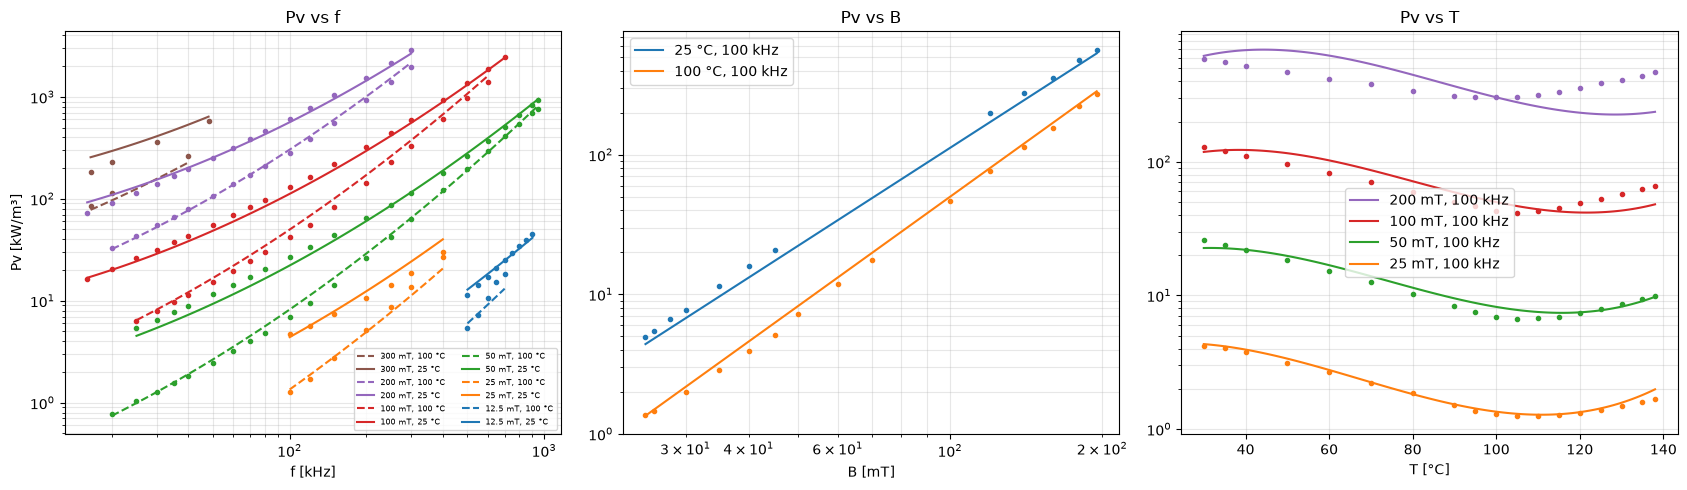

In [7]:
def Pv(f, B_T, T, theta=th, names=FINAL):
    out = np.exp(mat.feats(f, B_T, T, names) @ theta)
    return out.reshape(np.broadcast(np.asarray(f), np.asarray(B_T), np.asarray(T)).shape)

s = mat.s; Bl_ = sorted({e[0] for e in s['fsw']}); Tl_ = sorted({e[1] for e in s['fsw']})
col = {B: f'C{i}' for i, B in enumerate(Bl_)}; sty = dict(zip(Tl_, ['-', '--', '-.', ':']))
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for B, T, f, P in s['fsw']:
    ff = np.geomspace(min(f), max(f), 120)
    ax[0].loglog(f, P, 'o', ms=3, color=col[B]); ax[0].loglog(ff, Pv(ff, B/1000, T), sty[T], color=col[B], label=f'{B:g} mT, {T:g} °C')
ax[0].set(xlabel='f [kHz]', ylabel='Pv [kW/m³]', title='Pv vs f'); ax[0].legend(fontsize=6, ncol=2)
for i, (T, f0, Bl, P) in enumerate(s['bsw']):
    bb = np.geomspace(min(Bl), max(Bl), 60)
    ax[1].loglog(Bl, P, 'o', ms=3, color=f'C{i}'); ax[1].loglog(bb, Pv(f0, bb/1000, T), color=f'C{i}', label=f'{T:g} °C, {f0:g} kHz')
ax[1].set(xlabel='B [mT]', title='Pv vs B'); ax[1].legend()
for B, f0, Tl, P in s['tsw']:
    tt = np.linspace(min(Tl), max(Tl), 120)
    ax[2].semilogy(Tl, P, 'o', ms=3, color=col.get(B, 'k')); ax[2].semilogy(tt, Pv(f0, B/1000, tt), color=col.get(B, 'k'), label=f'{B:g} mT, {f0:g} kHz')
ax[2].set(xlabel='T [°C]', title='Pv vs T'); ax[2].legend()
for a in ax: a.grid(True, which='both', alpha=.3)
plt.tight_layout(); plt.show()

In [8]:
# Error per curve
out = []; D = mat.D; nf, nb = len(s['fsw']), len(s['bsw'])
for g_ in range(1, mat.ng + 1):
    m = D[:, 4] == g_; r = mat.feats(D[m, 0], D[m, 1]/1000, D[m, 2], FINAL) @ th - np.log(D[m, 3])
    kind = 'Pv vs f' if g_ <= nf else ('Pv vs B' if g_ <= nf + nb else 'Pv vs T')
    out.append({'curve': g_, 'plot': kind, 'B [mT]': 'sweep' if kind == 'Pv vs B' else D[m, 1][0],
                'T [°C]': 'sweep' if kind == 'Pv vs T' else D[m, 2][0], 'f [kHz]': 'sweep' if kind == 'Pv vs f' else D[m, 0][0],
                'n': int(m.sum()), 'rms %': round(rms(r), 1), 'max %': round(100*np.max(np.abs(np.exp(r) - 1)), 1)})
pd.DataFrame(out)

,curve,plot,B [mT],T [°C],f [kHz],n,rms %,max %
0,1,Pv vs f,300.0,100.0,sweep,3,12.7,15.1
1,2,Pv vs f,300.0,25.0,sweep,4,25.6,39.8
2,3,Pv vs f,200.0,100.0,sweep,15,5.8,10.4
3,4,Pv vs f,200.0,25.0,sweep,16,11.2,27.8
4,5,Pv vs f,100.0,100.0,sweep,17,13.7,23.2
5,6,Pv vs f,100.0,25.0,sweep,20,9.5,14.2
6,7,Pv vs f,50.0,100.0,sweep,22,9.2,19.0
7,8,Pv vs f,50.0,25.0,sweep,21,12.9,19.2
8,9,Pv vs f,25.0,100.0,sweep,7,12.4,22.2
9,10,Pv vs f,25.0,25.0,sweep,7,20.0,32.9


## 6. Steinmetz coefficients at any operating point

`local_steinmetz` gives the classic $k,\alpha,\beta$ valid *around one operating point* (local slopes of the fitted surface), for use in a Steinmetz-based design calculation. `t_min` finds the temperature of lowest loss at a given $f$ and $\hat B$. Use points inside the data range of the chosen material (see the plots above).

In [9]:
def local_steinmetz(f_kHz, B_T, T_C, eps=1e-4):
    lnP = lambda f, B: np.log(Pv(f, B, T_C))
    alpha = (lnP(f_kHz*np.exp(eps), B_T) - lnP(f_kHz*np.exp(-eps), B_T)) / (2*eps)
    beta  = (lnP(f_kHz, B_T*np.exp(eps)) - lnP(f_kHz, B_T*np.exp(-eps))) / (2*eps)
    k = float(Pv(f_kHz, B_T, T_C)) / (f_kHz**alpha * B_T**beta)    # kW/m3, f in kHz, B in T
    return dict(k=k, alpha=alpha, beta=beta, k_SI=1e3 * k * (1e-3)**alpha)   # k_SI: W/m3, f in Hz, B in T

Tlo_, Thi_ = min(mat.D[:, 2]), max(mat.D[:, 2])
def t_min(f_kHz, B_T, lo=Tlo_, hi=Thi_):
    TT = np.linspace(lo, hi, 441); return TT[np.argmin(Pv(f_kHz, B_T, TT))]

f_lo, f_hi = mat.D[:, 0].min(), mat.D[:, 0].max()
ops = [(mat.F0, .1, s['Tlo']), (mat.F0, .1, s['Thi']), (mat.F0, .05, s['Thi']), (mat.F0, .2, s['Thi'])]
rows = []
for f_, B_, T_ in ops:
    r = local_steinmetz(f_, B_, T_)
    rows.append({'f kHz': f_, 'B mT': B_*1000, 'T °C': T_, 'Pv kW/m3': round(float(Pv(f_, B_, T_)), 1),
                 'alpha': round(r['alpha'], 2), 'beta': round(r['beta'], 2), 'k_SI': '%.3g' % r['k_SI'],
                 'T of min loss': round(t_min(f_, B_), 0)})
pd.DataFrame(rows)

,f kHz,B mT,T °C,Pv kW/m3,alpha,beta,k_SI,T of min loss
0,100,100.0,25,111.8,1.30,2.33,7.7,122.0
1,100,100.0,100,49.9,1.68,2.61,0.0837,122.0
2,100,50.0,100,8.2,1.72,2.61,0.0487,116.0
3,100,200.0,100,303.7,1.63,2.61,0.144,128.0


## 7. Cross-check with a general-purpose optimiser

The least-squares solve above is exact because the model is linear in $\theta$ after taking logs. As an independent check, the same weighted problem is handed to `scipy.optimize.least_squares` (Levenberg-Marquardt) starting from zero. A second run minimises the *relative error in Pv itself* (not in ln Pv), starting from the log-domain solution; the two should agree closely, and the second shows how little the choice of error measure matters here.

In [10]:
from scipy.optimize import least_squares
A_, b_, w_ = mat.build(FINAL)
r1 = least_squares(lambda t: w_*(A_@t - b_), np.zeros(len(FINAL)), method='lm')
r2 = least_squares(lambda t: w_*(np.exp(A_@t) - np.exp(b_))/np.exp(b_), th, method='lm')
print('max |theta_lstsq - theta_least_squares(ln domain)| =', np.abs(r1.x - th).max())
print(f'rms error: lstsq {rms(A_@th-b_):.2f} %   optimiser(ln) {rms(A_@r1.x-b_):.2f} %   optimiser(relative Pv) {rms(A_@r2.x-b_):.2f} %')
pd.DataFrame({'lstsq': th, 'optimiser ln': r1.x, 'optimiser rel. Pv': r2.x}, index=FINAL).round(4).T

max |theta_lstsq - theta_least_squares(ln domain)| = 3.6958819338295257e-09
rms error: lstsq 14.66 %   optimiser(ln) 14.66 %   optimiser(relative Pv) 14.03 %


,1,x,x2,y,xy,t,t3,t2x,t2y
lstsq,4.2695,1.7336,0.1443,2.6469,-0.0680,-1.1685,0.8100,-0.5168,-0.3715
optimiser ln,4.2695,1.7336,0.1443,2.6469,-0.0680,-1.1685,0.8100,-0.5168,-0.3715
optimiser rel. Pv,4.2024,1.7273,0.1503,2.6257,-0.0476,-1.0516,0.5988,-0.5107,-0.3798


## 8. All materials in this file

In [11]:
rows = []
for name in MATERIALS:
    m_ = Material(name); fin = canon(m_.s['order']); th_, A_, b_ = m_.fit(fin)
    rows.append({'material': name, 'points': len(m_.D), 'curves': m_.ng, 'terms': len(fin),
                 'rms % in-sample': round(rms(A_ @ th_ - b_), 1), 'rms % leave-one-curve-out': round(m_.loco_cv(fin), 1),
                 'f range kHz': f'{m_.D[:,0].min():g}-{m_.D[:,0].max():g}', 'B range mT': f'{m_.D[:,1].min():g}-{m_.D[:,1].max():g}',
                 'T range °C': f'{m_.D[:,2].min():g}-{m_.D[:,2].max():g}'})
pd.DataFrame(rows)

,material,points,curves,terms,rms % in-sample,rms % leave-one-curve-out,f range kHz,B range mT,T range °C
0,N95,207,16,14,6.1,7.9,14.6-800,25-300,25-135
1,N27,247,17,10,4.9,6.1,2-200,25-300,20-115
2,N92,224,16,14,10.9,13.6,27-950,25-300,25-136
3,N88,326,22,9,10.2,12.3,25-500,25-300,25-150
4,N87,224,14,11,6.7,9.2,25-500,25-200,25-119
5,N97,245,18,9,14.7,17.0,16-950,12.5-300,25-138


**Validity.** Use each material's model only inside its digitized ranges (table above). The temperature dependence at frequencies other than the one used in the temperature sweep is only constrained by the f-sweep temperatures, so it is interpolated elsewhere. The higher-order terms extrapolate badly outside the data.